### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [179]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [123]:
data = pd.read_csv('data/coupons.csv')

In [124]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [125]:
#Overview of the data
data.info()

#The age column should be converted to an integer
data['age'].unique()

#Further inspections shows that the values of age are irregular. To simplify this I changed some values to make them integers. 
#If this causes issues down the line I can always revert.
data ['age'] = data['age'].replace({'50plus' : 50, 'below21' : 20})

data['age'] = pd.to_numeric(data['age']).astype('int64')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [126]:
data.describe()

,temperature,age,has_children,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
count,12684.000000,12684.000000,12684.000000,12684.0,12684.000000,12684.000000,12684.000000,12684.000000,12684.000000
mean,63.301798,32.296515,0.414144,1.0,0.561495,0.119126,0.214759,0.785241,0.568433
std,19.154486,10.187216,0.492593,0.0,0.496224,0.323950,0.410671,0.410671,0.495314
min,30.000000,20.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,55.000000,21.000000,0.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
50%,80.000000,31.000000,0.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
75%,80.000000,41.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
max,80.000000,50.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


In [127]:
#Number of null values per column
data.isnull().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

In [128]:
#Columns with null values with the number of affected rows.

# car                     12576
# Bar                       107
# CoffeeHouse               217
# CarryAway                 151
# RestaurantLessThan20      130
# Restaurant20To50          189

#Will be using these values to determine how to handle missing data in next cell.

#For each column with null values - found all unique values to assess how to handle invalid values.
null_cols = ['car', 'Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
for col in null_cols:
    print(f"Unique values in {col} Column: {data[col].unique()}")

Unique values in car Column: [nan 'Scooter and motorcycle' 'crossover' 'Mazda5' 'do not drive'
 'Car that is too old to install Onstar :D']
Unique values in Bar Column: ['never' 'less1' '1~3' 'gt8' nan '4~8']
Unique values in CoffeeHouse Column: ['never' 'less1' '4~8' '1~3' 'gt8' nan]
Unique values in CarryAway Column: [nan '4~8' '1~3' 'gt8' 'less1' 'never']
Unique values in RestaurantLessThan20 Column: ['4~8' '1~3' 'less1' 'gt8' nan 'never']
Unique values in Restaurant20To50 Column: ['1~3' 'less1' 'never' 'gt8' '4~8' nan]


3. Decide what to do about your missing data -- drop, replace, other...

The car column has the most null values. This column does not seem very useful since most of the values are blank and the few that are filled in do not provide a lot of useful information for any future analysis. Due to this I will drop the 'car' column from the dataset moving forward.

For the other columns ('Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50'), I will replace the null values with 'unknown'. This will avoid misrepresenting the data by putting these extra values into other groups and will hopefully better represent the real-world data without removing useful data.

In [129]:
#Work on null values in dataset

data_post_null = data.drop(columns=['car'])

data_post_null = data_post_null.fillna('unknown')

data_post_null.isnull().sum()


destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

4. What proportion of the total observations chose to accept the coupon?



Using value_counts we can get the proportion of people that accepted the coupon.
The value of 1 corresponds to people who DID accept the coupon.
The value of 0 corresponds to people who did NOT accept the coupon.

In [130]:
#Calculate proportion rates for total observations
proportion = data_post_null['Y'].value_counts()
proportion_normalized = data_post_null['Y'].value_counts(normalize=True)

print(f"The proportion of total observations that chose to accept the coupon is:\n{proportion}")
print(f"The normalize proportion of total observations that chose to accept the coupon is: \n{proportion_normalized}")

The proportion of total observations that chose to accept the coupon is:
1    7210
0    5474
Name: Y, dtype: int64
The normalize proportion of total observations that chose to accept the coupon is: 
1    0.568433
0    0.431567
Name: Y, dtype: float64


5. Use a bar plot to visualize the `coupon` column.

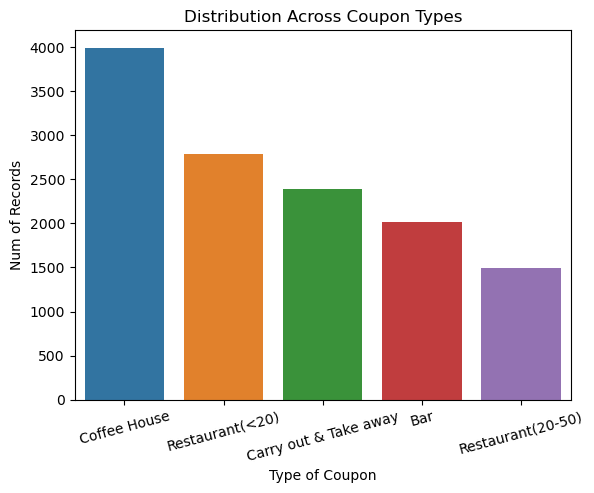

In [131]:
#Visualization of the distribution across coupon types

num_per_coupon = data_post_null['coupon'].value_counts()

sns.barplot(x=num_per_coupon.index, y=num_per_coupon.values)
plt.xticks(rotation=15)
plt.title('Distribution Across Coupon Types')
plt.xlabel('Type of Coupon')
plt.ylabel('Num of Records')
plt.show()

6. Use a histogram to visualize the temperature column.

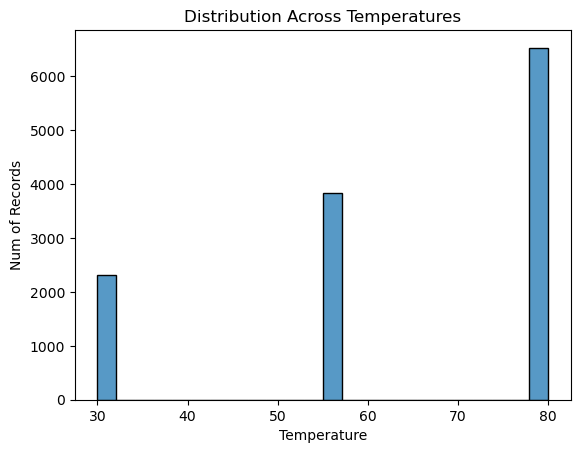

In [132]:
#Visualiztion of the distribution across temperatures
sns.histplot(data=data_post_null, x='temperature')
plt.title('Distribution Across Temperatures')
plt.xlabel('Temperature')
plt.ylabel('Num of Records')
plt.show()

I noticed this plot looked odd for a histogram so I looked into the data. 
Since the temperature column only includes [55, 80, 30] as values a histogram does not seem like the best representing plot. I followed this up with a count plot in the following cell to represent this data in another format.

Since there are only 3 possible values for temperature in this dataset, a countplot shows the same information as the above histogram, but I feel it is a more accurate representation of the data.

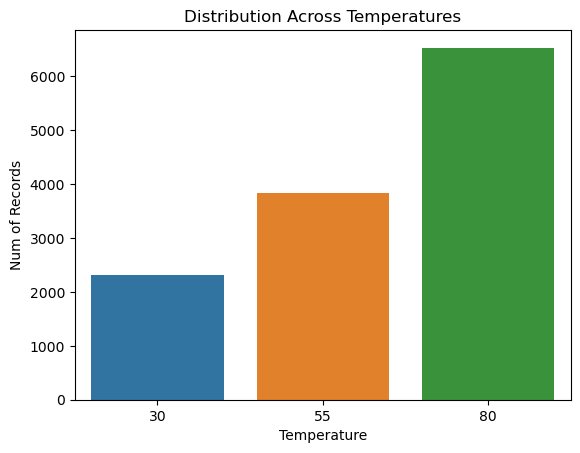

In [133]:
#Visualiztion of the distribution across temperatures as a count plot
sns.countplot(data=data_post_null, x='temperature')
plt.title('Distribution Across Temperatures')
plt.xlabel('Temperature')
plt.ylabel('Num of Records')
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [134]:
bar_coupons = data_post_null.query("coupon == 'Bar'")
bar_coupons.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


Using value_counts we can get the proportion of people that accepted the bar coupons. The value of 1 corresponds to people who DID accept the coupon. The value of 0 corresponds to people who did NOT accept the coupon.

The proportion of total observations that chose to accept the coupon is:
0    1190
1     827
Name: Y, dtype: int64
The normalize proportion of total observations that chose to accept the coupon is: 
0    0.589985
1    0.410015
Name: Y, dtype: float64


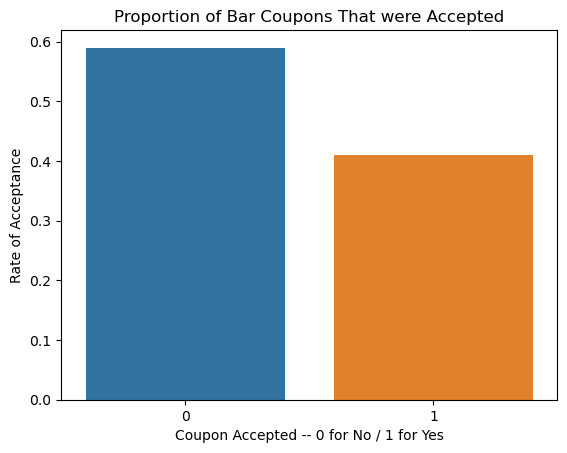

In [157]:
#Proportion of bar coupon acceptance and visualization
bar_proportion = bar_coupons['Y'].value_counts()
bar_proportion_normalized = bar_coupons['Y'].value_counts(normalize=True)

print(f"The proportion of total observations that chose to accept the coupon is:\n{bar_proportion}")
print(f"The normalize proportion of total observations that chose to accept the coupon is: \n{bar_proportion_normalized}")

sns.barplot(x=bar_proportion_normalized.index, y=bar_proportion_normalized.values)
plt.xlabel("Coupon Accepted -- 0 for No / 1 for Yes")
plt.ylabel("Rate of Acceptance")
plt.title("Proportion of Bar Coupons That were Accepted")
plt.show()

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


Rate of those who went to a bar 3 or fewer times a month and accepted: 0.37061769616026713
Rate of those who went to a bar more than 3 times a month and accepted: 0.7688442211055276


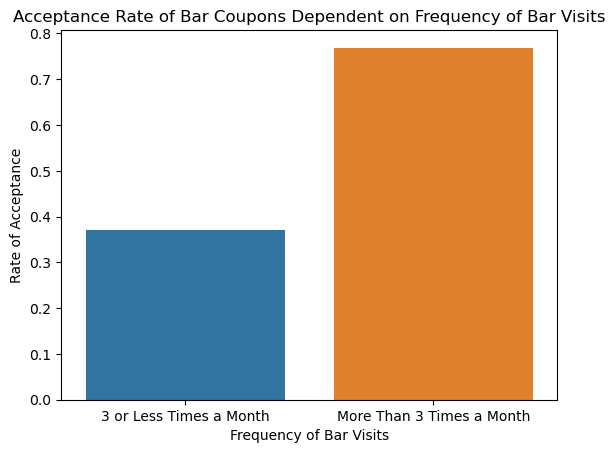

In [159]:
#Find unique values in the Bar column
bar_coupons['Bar'].unique()
#array(['never', 'less1', '1~3', 'gt8', 'unknown', '4~8'], dtype=object)

#Using the values in the Bar column - seperate into two groups to get number of acceptance dependent on frequency -- ignores values where the freq is unknown
bar_3_or_less_accept = bar_coupons.query("Bar in ['never', 'less1', '1~3']")['Y'].value_counts(normalize=True)
print(f"Rate of those who went to a bar 3 or fewer times a month and accepted: {bar_3_or_less_accept[1]}")

bar_more_than_3_accept = bar_coupons.query("Bar in ['4~8', 'gt8']")['Y'].value_counts(normalize=True)
print(f"Rate of those who went to a bar more than 3 times a month and accepted: {bar_more_than_3_accept[1]}")

sns.barplot(x=['3 or Less Times a Month', 'More Than 3 Times a Month'], y=[bar_3_or_less_accept[1], bar_more_than_3_accept[1]])
plt.xlabel("Frequency of Bar Visits")
plt.ylabel("Rate of Acceptance")
plt.title("Acceptance Rate of Bar Coupons Dependent on Frequency of Bar Visits")
plt.show()

The rate of acceptances is nearly doubled for people who go to bars more than 3 times a month.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Rate for frequent bar goers and people over 25: 0.6952380952380952
Infrequent bar goers and people under 25: 0.3944954128440367


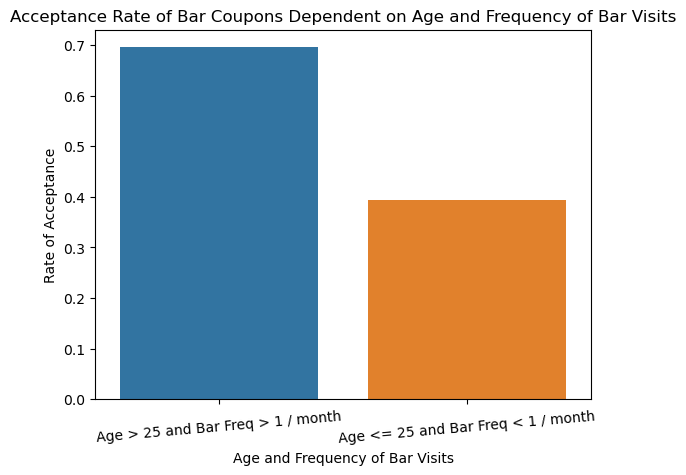

In [160]:
bar_freq_and_age_high = bar_coupons.query("Bar in ['1~3', 'gt8', '4~8'] and age > 25")['Y'].value_counts(normalize=True)
bar_freq_and_age_low = bar_coupons.query("Bar in ['never', 'less1'] and age <= 25")['Y'].value_counts(normalize=True)

print(f"Rate for frequent bar goers and people over 25: {bar_freq_and_age_high[1]}")
print(f"Infrequent bar goers and people under 25: {bar_freq_and_age_low[1]}")

sns.barplot(x=['Age > 25 and Bar Freq > 1 / month', 'Age <= 25 and Bar Freq < 1 / month'], y=[bar_freq_and_age_high[1], bar_freq_and_age_low[1]])
plt.xlabel("Age and Frequency of Bar Visits")
plt.xticks(rotation=5)
plt.ylabel("Rate of Acceptance")
plt.title("Acceptance Rate of Bar Coupons Dependent on Age and Frequency of Bar Visits")
plt.show()

The rate of acceptances is higher for people who frequent bars and are older


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [138]:
#For each column in this comparison - found all unique values to write the queries.
cols = ['Bar', 'passanger', 'occupation']
for col in cols:
    print(f"Unique values in {col} Column: {bar_coupons[col].unique()}")

Unique values in Bar Column: ['never' 'less1' '1~3' 'gt8' 'unknown' '4~8']
Unique values in passanger Column: ['Kid(s)' 'Alone' 'Friend(s)' 'Partner']
Unique values in occupation Column: ['Unemployed' 'Architecture & Engineering' 'Student'
 'Education&Training&Library' 'Healthcare Support'
 'Healthcare Practitioners & Technical' 'Sales & Related' 'Management'
 'Arts Design Entertainment Sports & Media' 'Computer & Mathematical'
 'Life Physical Social Science' 'Personal Care & Service'
 'Community & Social Services' 'Office & Administrative Support'
 'Construction & Extraction' 'Legal' 'Retired'
 'Installation Maintenance & Repair' 'Transportation & Material Moving'
 'Business & Financial' 'Protective Service'
 'Food Preparation & Serving Related' 'Production Occupations'
 'Building & Grounds Cleaning & Maintenance' 'Farming Fishing & Forestry']


Rate for query acceptance: 0.7132486388384754
Rate for all others acceptance:: 0.3333333333333333


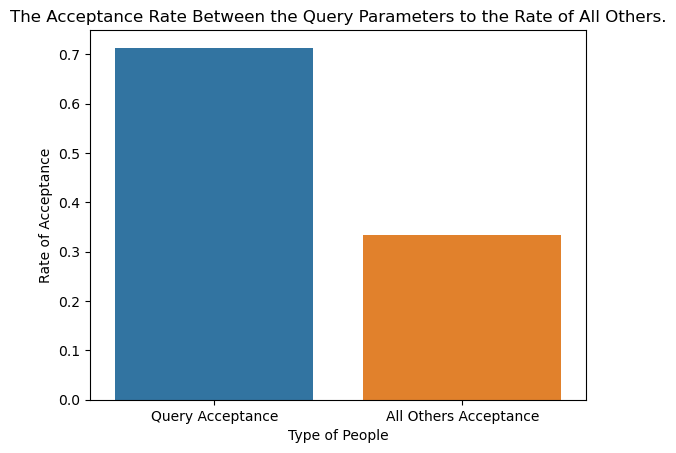

In [161]:
#Query to find drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.
query_acceptance_rate = bar_coupons.query("Bar in ['1~3', 'gt8', '4~8'] and passanger != 'Kid(s)' and occupation != 'Farming Fishing & Forestry'")['Y'].value_counts(normalize=True)[1]
not_query_acceptance_rate = bar_coupons.query("Bar in ['never', 'less1'] and passanger == 'Kid(s)' and occupation == 'Farming Fishing & Forestry'")['Y'].value_counts(normalize=True)[1]

print(f"Rate for query acceptance: {query_acceptance_rate}")
print(f"Rate for all others acceptance:: {not_query_acceptance_rate}")

sns.barplot(x=['Query Acceptance', 'All Others Acceptance'], y=[query_acceptance_rate, not_query_acceptance_rate])
plt.xlabel("Type of People")
plt.ylabel("Rate of Acceptance")
plt.title("The Acceptance Rate Between the Query Parameters to the Rate of All Others.")
plt.show()

The acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry is nearly double compared to the rate of all others.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [140]:
print("All columns: ", bar_coupons.columns)
#For each column in this comparison - found all unique values to write the queries.
cols = ['Bar', 'passanger', 'maritalStatus', 'age', 'RestaurantLessThan20', 'income']
for col in cols:
    print(f"Unique values in {col} Column: {bar_coupons[col].unique()}")

All columns:  Index(['destination', 'passanger', 'weather', 'temperature', 'time', 'coupon',
       'expiration', 'gender', 'age', 'maritalStatus', 'has_children',
       'education', 'occupation', 'income', 'Bar', 'CoffeeHouse', 'CarryAway',
       'RestaurantLessThan20', 'Restaurant20To50', 'toCoupon_GEQ5min',
       'toCoupon_GEQ15min', 'toCoupon_GEQ25min', 'direction_same',
       'direction_opp', 'Y'],
      dtype='object')
Unique values in Bar Column: ['never' 'less1' '1~3' 'gt8' 'unknown' '4~8']
Unique values in passanger Column: ['Kid(s)' 'Alone' 'Friend(s)' 'Partner']
Unique values in maritalStatus Column: ['Unmarried partner' 'Single' 'Married partner' 'Divorced' 'Widowed']
Unique values in age Column: [21 46 26 31 41 50 36 20]
Unique values in RestaurantLessThan20 Column: ['4~8' '1~3' 'less1' 'gt8' 'unknown' 'never']
Unique values in income Column: ['$37500 - $49999' '$62500 - $74999' '$12500 - $24999' '$75000 - $87499'
 '$50000 - $62499' '$25000 - $37499' '$100000 or More' 

Acceptance Rate of Query1: 0.7132486388384754
Acceptance Rate of Query2: 0.7217391304347827
Acceptance Rate of Query3: 0.45348837209302323


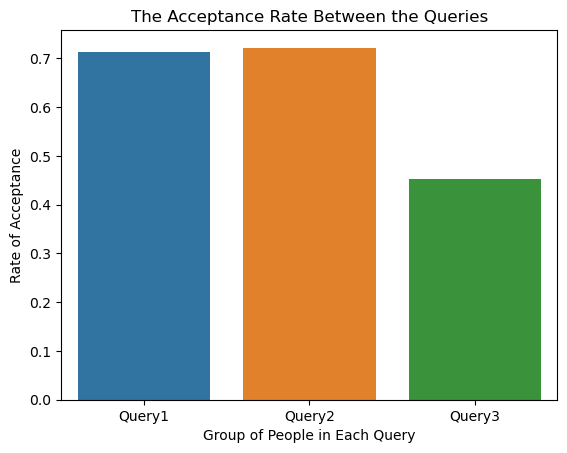

In [162]:
#Query1 = go to bars more than once a month, had passengers that were not a kid, and were not widowed
Query1 = bar_coupons.query("Bar in ['1~3', 'gt8', '4~8'] and passanger != 'Kid(s)' and maritalStatus != 'Widowed'")
Query1_accept_rate = Query1['Y'].value_counts(normalize=True)[1]
print(f"Acceptance Rate of Query1: {Query1_accept_rate}")
      
#Query2 = go to bars more than once a month and are under the age of 30
Query2 = bar_coupons.query("Bar in ['1~3', 'gt8', '4~8'] and age < 30")
Query2_accept_rate = Query2['Y'].value_counts(normalize=True)[1]
print(f"Acceptance Rate of Query2: {Query2_accept_rate}")
      
#Query3 =  go to cheap restaurants more than 4 times a month and income is less than 50K.
Query3 = bar_coupons.query("RestaurantLessThan20 in ['4~8', 'gt8'] and income in ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999']")
Query3_accept_rate = Query3['Y'].value_counts(normalize=True)[1]
print(f"Acceptance Rate of Query3: {Query3_accept_rate}")

sns.barplot(x=['Query1', 'Query2', 'Query3'], y=[Query1_accept_rate, Query2_accept_rate, Query3_accept_rate])
plt.xlabel("Group of People in Each Query")
plt.ylabel("Rate of Acceptance")
plt.title("The Acceptance Rate Between the Queries")
plt.show()

The acceptance rate is highest in the second query group. It is very close to the first query group with a difference of roughly 
.008. The 3rd query group does not seem a strong indicator for the acceptance rate.

This shows that the people who go to bars more than once a month and are under the age of 30 are most likely to accept bar coupons 
relative to those who go to bars more than once a month, had passengers that were not a kid, and were not widowed or those who go to cheap 
restaurants more than 4 times a month and have an income of less than 50K.

The most important takeaway is that it seems the most reliable factor to determine bar coupon acceptance is the frequency that people visit bars
in a month since that is the common factor between Query1 and Query 2 that Query3 is missing.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

#### Bar Coupon Conclusion:

**Findings:**

I hypothesis that people who visit bars more than 3 times a month and are older than 21 are the most likely to accept bar coupons. 
Additionally, I would say bar frequency and age the most important factors for bar coupons and can be a strong indicator for whether a person will accept a bar coupon since queries and analysis where these factors are present yield higher acceptance rates.
This conclusion makes sense since those who are more likely to use the coupons in the future should be the ones most likely to accept, unlike those who will never use the coupons.

**Recommedations:**

Moving forward, I think bars that want to give these types of coupons should aim for targeting specific customers or give increased rewards for certain groups.
Since customers that frequent bars more than 3 times a month and are above the age of 21 are most likely to accept, bars should focus on giving more coupons to these specific groups.
Additionally, if bars want to reach out to a larger audience, they may need to provide increased incentives for people who rarely visit bars or are under the age of 21. This could include more free food or discounts on any additional activies in or even around the bar area.

**Next Steps:**

In general, I would advise these companies should focus on strategies to increase the frequency of current customers or additional incentives to bring in newer customers. The more often people frequent their establishments, the more likely they will accept these coupons.
Some examples could be in provided more discounts for drinks and foods, and if the bar includes any additional activies then also providing discounts for these as well. Additionally, the bar should reach out to other businesses around the area to work together to bring more people to the area. This could include restaurants, bowling alleys, movie theaters, etc. If these organization come to an agreement, they could offer group discounts on a variety of activies to incentivise more customers to come to the area. This would benefit the bar company since it would bring people who otherwise would not be interested in bar coupons and increase the overall population and frequency of bar visits.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

**Investigating the Coffee House Coupons**

Will begin by looking into the data to find possible trends for analysis

Create a new DataFrame that contains just the Coffee House coupons.

In [163]:
#Seperate the coffee house coupons in the data set for further analysis.
coffee_house_coupons = data_post_null.query("coupon == 'Coffee House'")

coffee_house_coupons.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,0,0,0,1,0
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,1,0,0,1,0
12,No Urgent Place,Kid(s),Sunny,55,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,1,0,0,1,1
15,Home,Alone,Sunny,80,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,unknown,4~8,1~3,1,0,0,0,1,0


What proportion of Coffee House coupons were accepted?

Using value_counts we can get the proportion of people that accepted the coffee house coupons. 

The value of 1 corresponds to people who DID accept the coupon.
The value of 0 corresponds to people who did NOT accept the coupon.

The proportion of total observations that chose to accept the coupon is:
0    2001
1    1995
Name: Y, dtype: int64
The normalized proportion of total observations that chose to accept the coupon is: 
0    0.500751
1    0.499249
Name: Y, dtype: float64


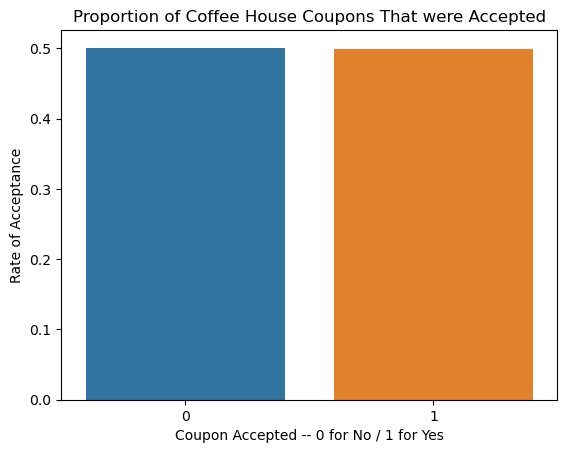

In [166]:
#prportion of coffee house coupons accepted
coffee_proportion = coffee_house_coupons['Y'].value_counts()
coffee_proportion_normalized = coffee_house_coupons['Y'].value_counts(normalize=True)

print(f"The proportion of total observations that chose to accept the coupon is:\n{coffee_proportion}")
print(f"The normalized proportion of total observations that chose to accept the coupon is: \n{coffee_proportion_normalized}")

sns.barplot(x=coffee_proportion_normalized.index, y=coffee_proportion_normalized.values)
plt.xlabel("Coupon Accepted -- 0 for No / 1 for Yes")
plt.ylabel("Rate of Acceptance")
plt.title("Proportion of Coffee House Coupons That were Accepted")
plt.show()

Unlike the bar coupons which were mostly rejected, the rate of acceptance of coffee house coupons is roughly 50/50.

In [145]:
#Look into each column to find potential for trends and indicators
print("Columns: ", coffee_house_coupons.columns)

Columns:  Index(['destination', 'passanger', 'weather', 'temperature', 'time', 'coupon',
       'expiration', 'gender', 'age', 'maritalStatus', 'has_children',
       'education', 'occupation', 'income', 'Bar', 'CoffeeHouse', 'CarryAway',
       'RestaurantLessThan20', 'Restaurant20To50', 'toCoupon_GEQ5min',
       'toCoupon_GEQ15min', 'toCoupon_GEQ25min', 'direction_same',
       'direction_opp', 'Y'],
      dtype='object')


**Columns for further analysis - CoffeeHouse, Weather/Temp, Occupation, Income, toCoupon_GEQ5min/15/25**

In [146]:
#Find all unique values for each important column

coffee_cols = ['CoffeeHouse', 'weather', 'income', 'toCoupon_GEQ15min', 'toCoupon_GEQ25min']

for col in coffee_cols:
    print(f"Unique values in {col} Column: {coffee_house_coupons[col].unique()}")
    print(f"Type of column values: {type(col[0])}")

Unique values in CoffeeHouse Column: ['never' 'less1' '4~8' '1~3' 'gt8' 'unknown']
Type of column values: <class 'str'>
Unique values in weather Column: ['Sunny' 'Rainy' 'Snowy']
Type of column values: <class 'str'>
Unique values in income Column: ['$37500 - $49999' '$62500 - $74999' '$12500 - $24999' '$75000 - $87499'
 '$50000 - $62499' '$25000 - $37499' '$100000 or More' '$87500 - $99999'
 'Less than $12500']
Type of column values: <class 'str'>
Unique values in toCoupon_GEQ15min Column: [0 1]
Type of column values: <class 'str'>
Unique values in toCoupon_GEQ25min Column: [0 1]
Type of column values: <class 'str'>


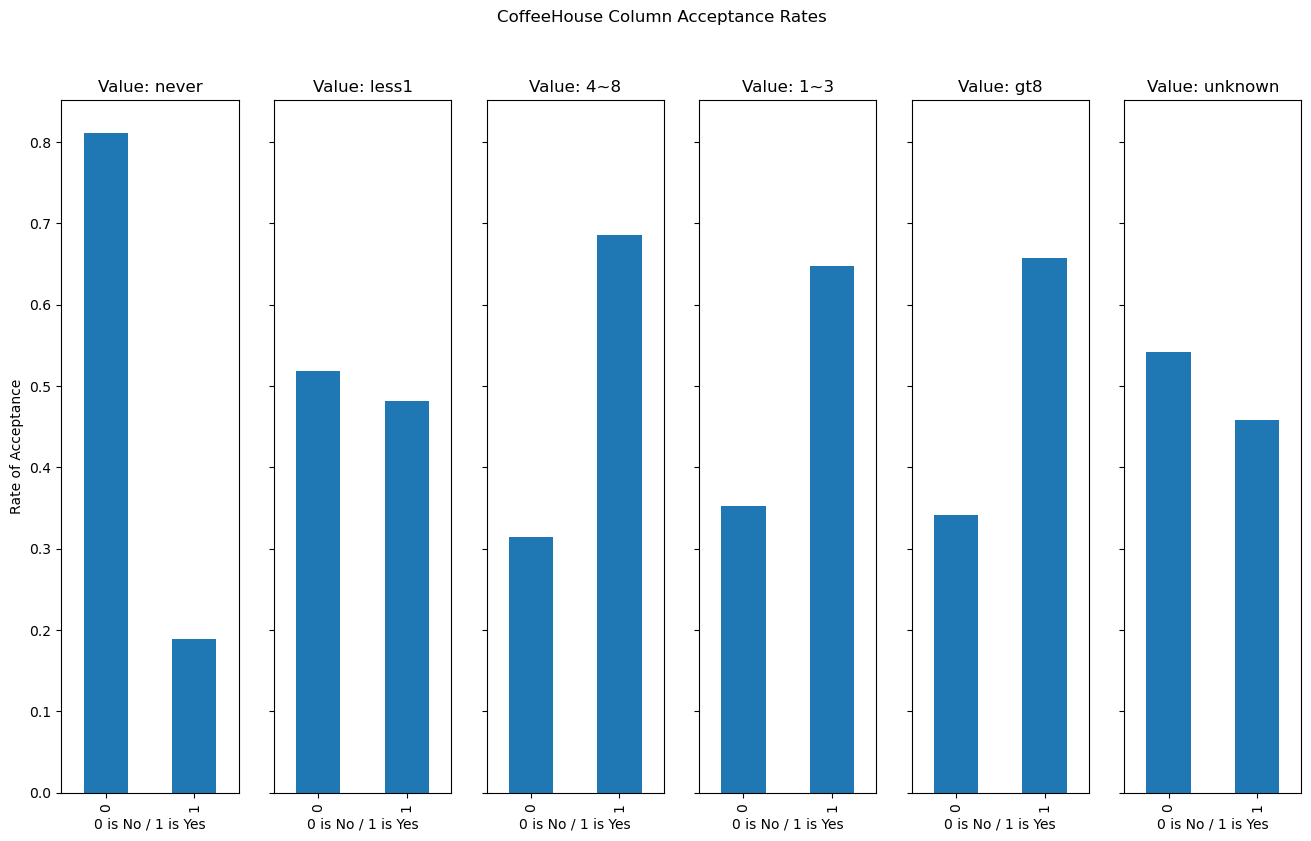

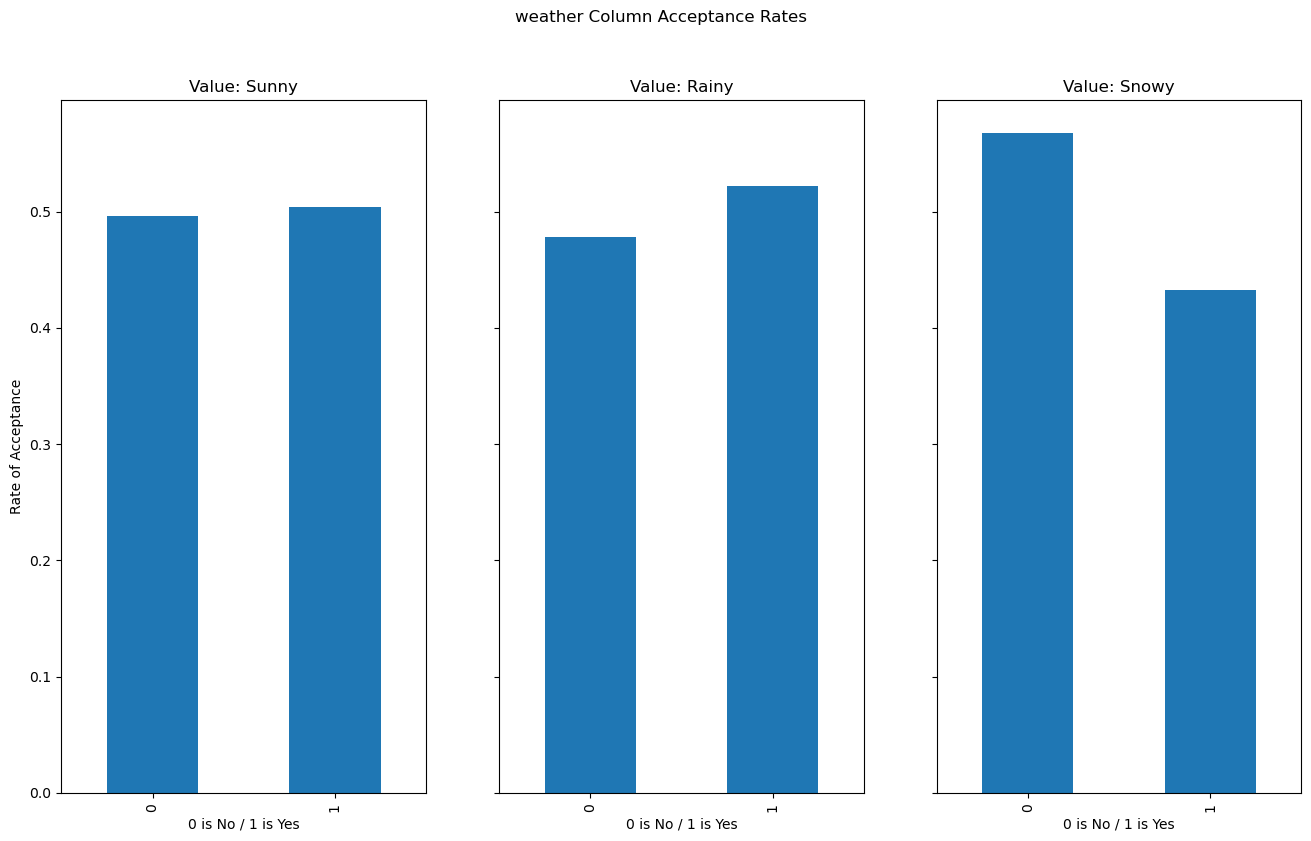

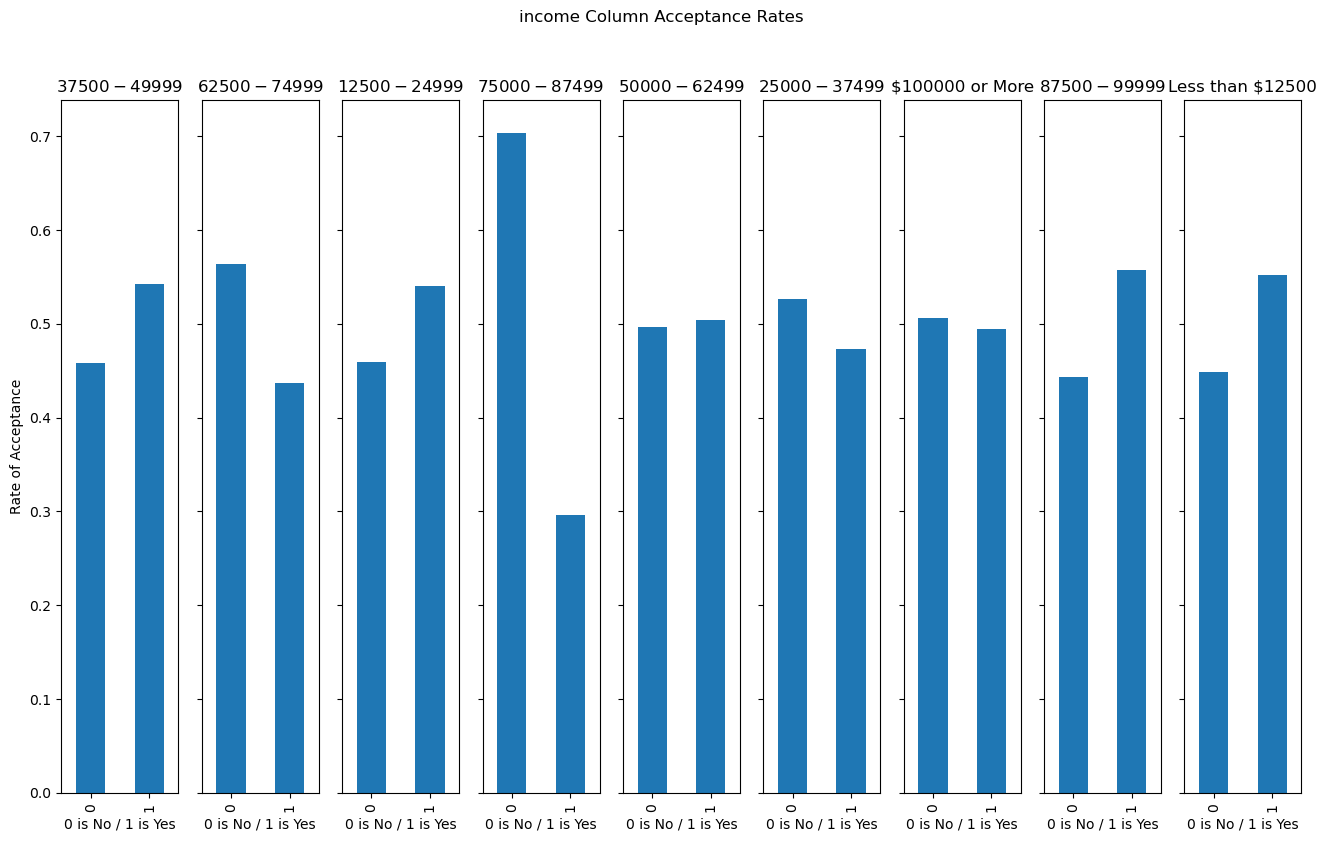

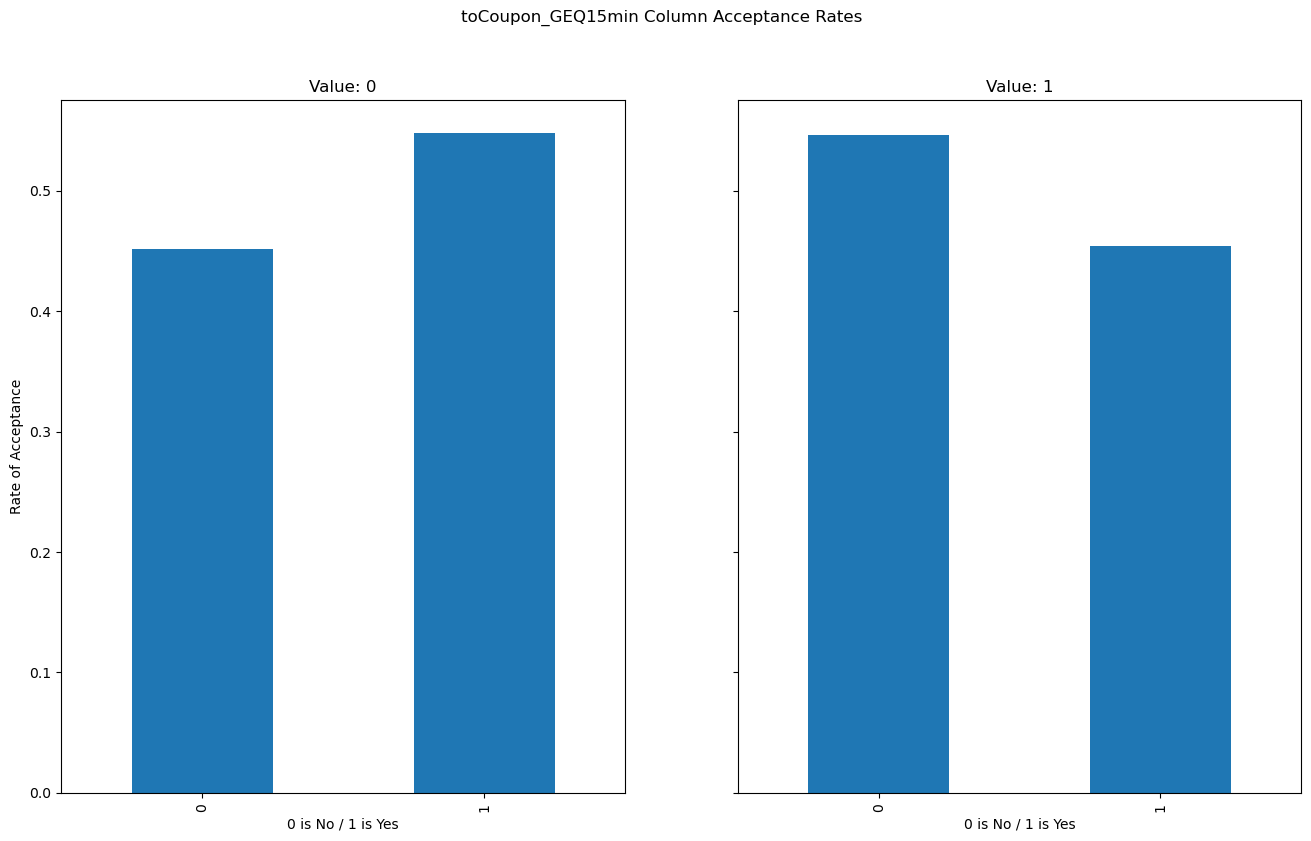

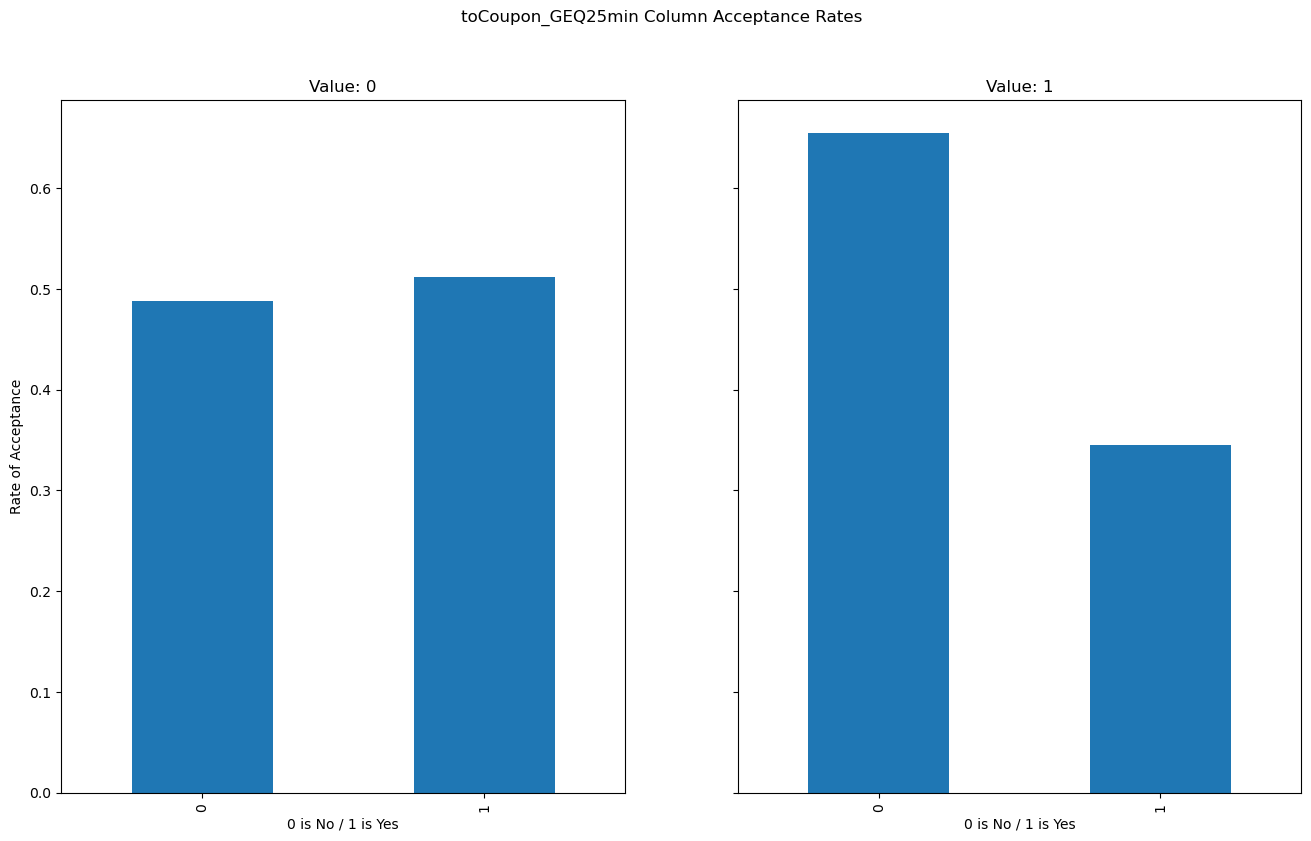

In [174]:
# Closer look at each of my 'imortant' columns to find trends and combinations that could achiever higher acceptance rates
# Each column - evaluate and plot acceptance rate for each value using subplots

for col in coffee_cols:
    fig, axs = plt.subplots(1, len(coffee_house_coupons[col].unique()), figsize=(16,9), sharey='all')
    axis = 0
    fig.suptitle(f"{col} Column Acceptance Rates")
    for val in coffee_house_coupons[col].unique():
        if type(val) is str:
            normalized_proportion = coffee_house_coupons.query(f"{col} == '{val}'")['Y'].value_counts(normalize=True)   
        else:
            normalized_proportion = coffee_house_coupons.query(f"{col} == {val}")['Y'].value_counts(normalize=True)
        
        normalized_proportion.sort_index().plot(ax=axs[axis], kind='bar')
        
        if col == "income":
            axs[axis].set_title(f"{val}")
        else:     
            axs[axis].set_title(f"Value: {val}")
            
        axs[axis].set_xlabel("0 is No / 1 is Yes")
        axs[axis].set_ylabel("Rate of Acceptance")
        axis += 1

### Individual columns analysis: 

**Compare the acceptance rate between those who went to a coffee house 4 or more times a month to those who went less.**

Rate of those who went to a Coffee House 4 or more times a month and accepted: 0.675
Rate of those who went to a Coffee House less than 4 times a month and accepted: 0.44940867279894875


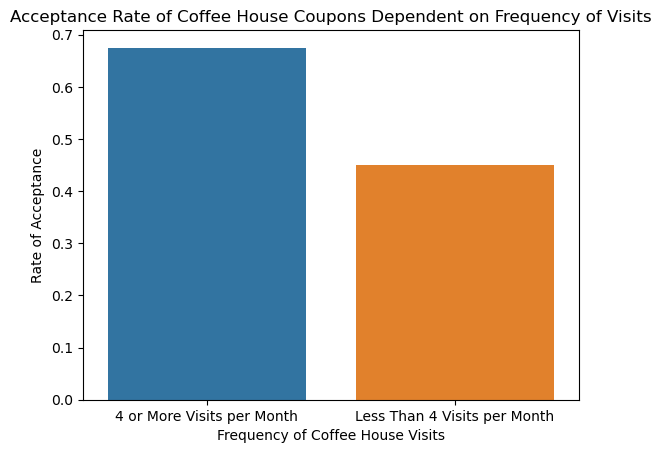

In [175]:
#Find unique values in the CoffeeHouse column
coffee_house_coupons['CoffeeHouse'].unique()
#array(['never', 'less1', '1~3', 'gt8', 'unknown', '4~8'], dtype=object)

#Using the values in the Bar column - seperate into two groups to get number of acceptance dependent on frequency -- ignores values where the freq is unknown
ch_4_or_more_accept = coffee_house_coupons.query("CoffeeHouse in ['4~8', 'gt8']")['Y'].value_counts(normalize=True)
print(f"Rate of those who went to a Coffee House 4 or more times a month and accepted: {ch_4_or_more_accept[1]}")

ch_less_than_4_accept = coffee_house_coupons.query("CoffeeHouse in ['never', 'less1', '1~3']")['Y'].value_counts(normalize=True)
print(f"Rate of those who went to a Coffee House less than 4 times a month and accepted: {ch_less_than_4_accept[1]}")

sns.barplot(x=['4 or More Visits per Month', 'Less Than 4 Visits per Month'], y=[ch_4_or_more_accept[1], ch_less_than_4_accept[1]])
plt.xlabel("Frequency of Coffee House Visits")
plt.ylabel("Rate of Acceptance")
plt.title("Acceptance Rate of Coffee House Coupons Dependent on Frequency of Visits")
plt.show()

The rate of acceptances is higher for people who go to bars more than 3 times a month.

**Compare the acceptance rate between those who went to a coffee house in snowy weather vs other weather condition.**

Rate of those who went to a Coffee House in snowy weather and accepted: 0.43234323432343236
Rate of those who went to a Coffee House in rainy or sunny weather and accepted: 0.5047386948280531


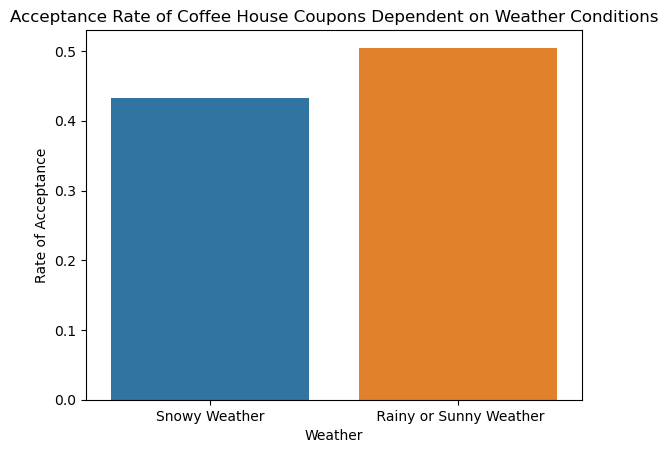

In [176]:
# Find all weather values
coffee_house_coupons['weather'].unique()
#array(['Sunny', 'Rainy', 'Snowy'], dtype=object)

#acceptance rate of snowy weather
ch_in_snow = coffee_house_coupons.query("weather == 'Snowy'")['Y'].value_counts(normalize=True)[1]

#acceptance rate of NOT snowy weather
ch_not_in_snow = coffee_house_coupons.query("weather in ['Sunny', 'Rainy']")['Y'].value_counts(normalize=True)[1]
                                            
print(f"Rate of those who went to a Coffee House in snowy weather and accepted: {ch_in_snow}")
print(f"Rate of those who went to a Coffee House in rainy or sunny weather and accepted: {ch_not_in_snow}")

sns.barplot(x=['Snowy Weather', ' Rainy or Sunny Weather'], y=[ch_in_snow, ch_not_in_snow])
plt.xlabel("Weather")
plt.ylabel("Rate of Acceptance")
plt.title("Acceptance Rate of Coffee House Coupons Dependent on Weather Conditions")
plt.show()

The acceptance rate is higher when the weather is rainy or sunny compared to snowy weather

**Compare the acceptance rate between those who went to a coffee house and have an income in the range of 75000-87499 vs all other income groups.**

Rate of those who went to a Coffee House and have an income in the range of $75000-87499 and accepted: 0.2966101694915254
Rate of those who went to a Coffee House with an income outside the range and accepted: 0.511968085106383


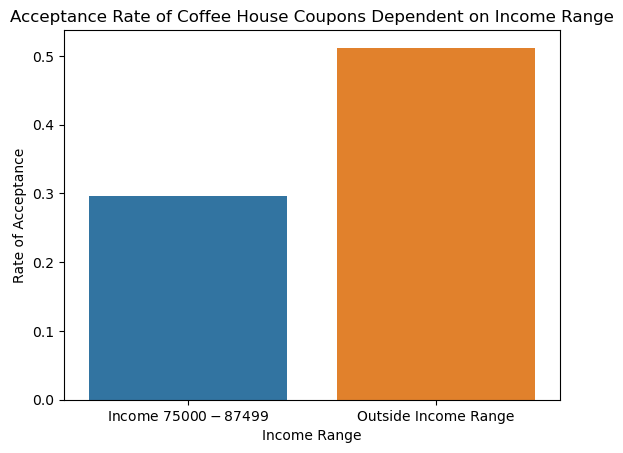

In [177]:
# Find all income values
coffee_house_coupons['income'].unique()
# array(['$37500 - $49999', '$62500 - $74999', '$12500 - $24999',
#        '$75000 - $87499', '$50000 - $62499', '$25000 - $37499',
#        '$100000 or More', '$87500 - $99999', 'Less than $12500'],
#       dtype=object)

#acceptance rate in range
ch_in_range = coffee_house_coupons.query("income == '$75000 - $87499'")['Y'].value_counts(normalize=True)[1]
ch_in_range

#acceptance rate not in range
ch_not_in_range = coffee_house_coupons.query("income != '$75000 - $87499'")['Y'].value_counts(normalize=True)[1]
ch_not_in_range

print(f"Rate of those who went to a Coffee House and have an income in the range of $75000-87499 and accepted: {ch_in_range}")
print(f"Rate of those who went to a Coffee House with an income outside the range and accepted: {ch_not_in_range}")

sns.barplot(x=['Income $75000 - $87499', 'Outside Income Range'], y=[ch_in_range, ch_not_in_range])
plt.xlabel("Income Range")
plt.ylabel("Rate of Acceptance")
plt.title("Acceptance Rate of Coffee House Coupons Dependent on Income Range")
plt.show()

The acceptance rate is suprisingly low for the income range \\$75,000 - \\$87,499 when compared to all other income ranges.

### Combined columns analysis w/ queries: 

**Compare the acceptance rates between those who:**

- go to coffee houses at least once a month when the weather was sunny and the driving time to the coupon venue is less than 15 minutes.
- go to coffee houses more than 3 times a month when the weather was rainy and the driving time to the coupon venue is less than 15 minutes.
- go to coffee houses less than 4 times a month have an income not in the 75000-87499 range and the driving time to the coupon venue is greater than or equal to 25 minutes.
- go to coffee houses less than 1 time a month when the weather was snowy and the driving time to the coupon venue is less than 25 minutes.

Query 1 Acceptance Rate: 0.7472527472527473
Query 2 Acceptance Rate: 0.5
Query 3 Acceptance Rate: 0.29955947136563876
Query 4 Acceptance Rate: 0.3287671232876712


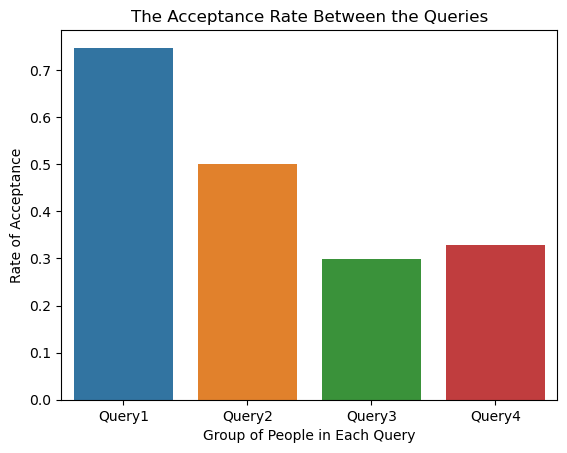

In [178]:
#Query1 - go to coffee houses at least once a month when the weather was sunny and the driving time to the coupon venue is less than 15 minutes.
query1 = coffee_house_coupons.query("CoffeeHouse in ['4~8', '1~3', 'gt8'] and weather == 'Sunny' and toCoupon_GEQ15min == 0")
query1_rate = query1['Y'].value_counts(normalize=True)[1]
print(f"Query 1 Acceptance Rate: {query1_rate}")
#Query2 - go to coffee houses more than 3 times a month when the weather was rainy and the driving time to the coupon venue is less than 15 minutes.
query2 = coffee_house_coupons.query("CoffeeHouse in ['4~8', 'gt8'] and weather == 'Rainy' and toCoupon_GEQ15min == 0")
query2_rate = query2['Y'].value_counts(normalize=True)[1]
print(f"Query 2 Acceptance Rate: {query2_rate}")
#Query3 - go to coffee houses less than 4 times a month have an income not in the 75000-87499 range and the driving time to the coupon venue is greater than or equal to 25 minutes.
query3 = coffee_house_coupons.query("CoffeeHouse in ['never', 'less1', '1~3'] and income != '$75000 - $87499' and toCoupon_GEQ25min == 1")
query3_rate = query3['Y'].value_counts(normalize=True)[1]
print(f"Query 3 Acceptance Rate: {query3_rate}")
#Query4 - go to coffee houses less than 1 time a month when the weather was snowy and the driving time to the coupon venue is less than 25 minutes.query3 = coffee_house_coupons.query("CoffeeHouse in ['never', 'less1', '1~3'] and income != '$75000 - $87499' and toCoupon_GEQ25min == 1")
query4 = coffee_house_coupons.query("CoffeeHouse in ['never', 'less1'] and weather == 'Snowy' and toCoupon_GEQ25min == 0")
query4_rate = query4['Y'].value_counts(normalize=True)[1]
print(f"Query 4 Acceptance Rate: {query4_rate}")

sns.barplot(x=['Query1', 'Query2', 'Query3', 'Query4'], y=[query1_rate, query2_rate, query3_rate, query4_rate])
plt.xlabel("Group of People in Each Query")
plt.ylabel("Rate of Acceptance")
plt.title("The Acceptance Rate Between the Queries")
plt.show()

These observations show that there seems to be a high correlation between the frequency of coffee house visits
with higher acceptance rates. There also seems to be a strong correlation between the weather and acceptance rates as 
people tend to accept the coupons more frequently when the weather is sunny. There are also some patterns related 
to the driving time combined with frequency that show when people go to coffee houses multiple times a month and the 
driving time is less than 15 minutes that they seem more likely to accept these types of coupons. Additionally, when the 
driving time is greater than or equal to 25 minutes there is a drop in coupon acceptance rates.

#### Coffee House Coupon Conclusion:

**Findings:**

I hypothesis that people who visit coffee houses at least once a month and have a driving time of less than 15 minutes are the most likely to accept coffee house coupons. 
Additionally, if the weather is sunny on the day the coupon is offered then people are more likely to accept. 
I would summarize that the most important factors to determine if a coffee house coupon will be accepted is the frequency of visits in a month, the weather conditions, and the total drive time to the coffee house. If all of these factors are met then the acceptance rate is nearly 75% which when compared to the total acceptance rate of roughly 50%, is a large improvement.

**Recommedations:**

I would recommend coffee houses to target specific customer segments when they offer coupons to increase acceptance rates. I would advise these organizations to focus on customers that visit coffee houses at least once a month and are within 15 minutes driving distance. These factors seem to have the highest weight in if a customer accepts or rejects a coupon. 

**Next Steps:**

For next steps, I would recommend offerring more coupons to customers who are regulars since they will be more likely to accept and come back in to use the coupon. 
If the goal is to bring in more and newer customers, then I would also advise to offer coupons to customers outside that demographic, but add extra incentives like if a customer brings in a friend they can get a buy-one-get-one free deal for drinks or meals.

#### Overall Conclusion:

**Findings:**

In general, it seems that regardless of coupon type, the customers who frequent establishments more often are more likely to accept these coupons. There are some additional factors that seem to have more of an impact with specific coupon types, but frequency is common across the board.
To answer the question of 'Will the Customer Accept the Coupon? ', there are multiple factors that should be taken into consideration, but it would be safe to assume that if the frequency of visits per month is 3 or more for a specific establishment, then the customer will most likely accept regardless of other factors.
I would further assume that if a customer frequents an establishment that often, then there are a few other features that we can predict. For example, if a customer frequents a bar more than 3 times a month, we could assume that they are above 21 years old and they are with a reasonable commute of 15 minutes driving time.

**Recommendations:**

Given the similarity of trends between coupon types I would offer roughly the same recommendations for each of the establishments in this data set.

For the goal of increasing coupon acceptance rate:
I would focus on offerring coupons to regulars that frequent these businesses at least 3 times per month.

For the goal of bringing in new customers with the coupon incentive:
I would increase incentives or work together with surrounding bussinesses to offer group discounts a deals to bring more and newer foot traffic to the areas.